# Projek Statistika dan Probabilitas
**Analisis Waktu Pengiriman dan Ongkos Kirim pada Data Pesanan E-Commerce Olist sebagai Dasar Perancangan Data Pipeline**

Kelas 3TIC - Kelompok 2 | Konsentrasi: Data Engineer

Dataset: [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

**Alur notebook:** (1) upload data -> (2) buat dataset -> (3) cek kualitas -> (4) statistika deskriptif -> (5) distribusi probabilitas -> (6) statistika inferensial -> (7) simpan hasil

## 1. Persiapan dan Upload Data
Jalankan sel di bawah, lalu pilih 2 file: `olist_orders_dataset.csv` dan `olist_order_items_dataset.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from google.colab import files

KELAS = "3TIC"
KELOMPOK = "02"
NAMA_DATA = "PesananOlist"

uploaded = files.upload()   # pilih olist_orders_dataset.csv dan olist_order_items_dataset.csv

Saving olist_orders_dataset.csv to olist_orders_dataset.csv


In [2]:
from google.colab import files

uploaded = files.upload()

Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv


## 2. Membuat Dataset
Kedua file digabung berdasarkan `order_id`, hanya pesanan `delivered` yang dipakai, lalu dihitung `waktu_pengiriman_hari`.

In [4]:
orders = pd.read_csv("olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date"])
items = pd.read_csv("olist_order_items_dataset.csv")

total_awal = len(items)
df = items.merge(orders, on="order_id", how="inner")

# hanya pesanan yang sudah sampai (punya tanggal diterima)
df = df[(df["order_status"] == "delivered") & df["order_delivered_customer_date"].notna()].copy()

# kolom turunan: waktu pengiriman (hari)
df["waktu_pengiriman_hari"] = (
    (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
).round(2)

kolom = ["order_id", "order_item_id", "product_id", "seller_id",
         "order_purchase_timestamp", "order_delivered_customer_date",
         "price", "freight_value", "waktu_pengiriman_hari"]
df = df[kolom].reset_index(drop=True)

print("Baris awal order_items:", total_awal)
print("Baris setelah filter  :", len(df), "| Kolom:", len(df.columns))
df.head()

Baris awal order_items: 112650
Baris setelah filter  : 110189 | Kolom: 9


,order_id,order_item_id,product_id,seller_id,order_purchase_timestamp,order_delivered_customer_date,price,freight_value,waktu_pengiriman_hari
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-13 08:59:02,2017-09-20 23:43:48,58.90,13.29,7.61
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-04-26 10:53:06,2017-05-12 16:04:24,239.90,19.93,16.22
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-14 14:33:31,2018-01-22 13:19:16,199.00,17.87,7.95
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-08 10:00:35,2018-08-14 13:32:39,12.99,12.79,6.15
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-04 13:57:51,2017-03-01 16:42:31,199.90,18.14,25.11


## 3. Pemeriksaan Kualitas Data

In [5]:
print("Jumlah baris:", len(df))
print("\nData kosong per kolom:")
print(df.isna().sum())
print("\nBaris kembar:", df.duplicated().sum())
print("Kembar order_id + order_item_id:", df.duplicated(["order_id", "order_item_id"]).sum())

VAR = ["price", "freight_value", "waktu_pengiriman_hari"]
NAMA = {"price": "Harga (BRL)", "freight_value": "Ongkos Kirim (BRL)", "waktu_pengiriman_hari": "Waktu Pengiriman (hari)"}
df[VAR].describe()

Jumlah baris: 110189

Data kosong per kolom:
order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
order_purchase_timestamp         0
order_delivered_customer_date    0
price                            0
freight_value                    0
waktu_pengiriman_hari            0
dtype: int64

Baris kembar: 0
Kembar order_id + order_item_id: 0


,price,freight_value,waktu_pengiriman_hari
count,110189.000000,110189.000000,110189.000000
mean,119.977937,19.948869,12.472224
std,182.304615,15.698615,9.445341
min,0.850000,0.000000,0.530000
25%,39.900000,13.080000,6.740000
50%,74.900000,16.260000,10.180000
75%,134.170000,21.150000,15.540000
max,6735.000000,409.680000,209.630000


### Simpan dataset ke Excel (untuk dikumpulkan)

In [ ]:
OUT_XLSX = f"{KELAS}_{KELOMPOK}_{NAMA_DATA}.xlsx"

kamus = pd.DataFrame([
 ["order_id","ID pesanan","Kualitatif","Nominal","-","Identitas"],
 ["order_item_id","Nomor urut item dalam pesanan","Kuantitatif","Diskrit","Rasio","item"],
 ["product_id","ID produk","Kualitatif","Nominal","-","Identitas"],
 ["seller_id","ID penjual","Kualitatif","Nominal","-","Identitas"],
 ["order_purchase_timestamp","Waktu pesanan dibuat","Waktu","Interval","Interval","tanggal-jam"],
 ["order_delivered_customer_date","Waktu pesanan diterima pelanggan","Waktu","Interval","Interval","tanggal-jam"],
 ["price","Harga item","Kuantitatif","Kontinu","Rasio","BRL (Real Brasil)"],
 ["freight_value","Ongkos kirim item","Kuantitatif","Kontinu","Rasio","BRL (Real Brasil)"],
 ["waktu_pengiriman_hari","Lama pengiriman = tanggal diterima - tanggal pesan","Kuantitatif","Kontinu","Rasio","hari"],
], columns=["Variabel","Keterangan","Jenis","Tipe","Skala","Satuan"])

info = pd.DataFrame({"Keterangan": [
 "Sumber: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (Olist), file olist_orders_dataset.csv & olist_order_items_dataset.csv",
 "Unit observasi: satu baris = satu item dalam pesanan",
 f"Jumlah baris awal order_items: {total_awal:,}; setelah difilter: {len(df):,}",
 "Filter: hanya order_status = delivered dan tanggal diterima tidak kosong",
 "Kolom turunan: waktu_pengiriman_hari (dihitung dari dua kolom tanggal)",
 "Missing value: tidak ada pada kolom yang dipakai setelah filter",
 "Data asli tidak diubah selain filter dan kolom turunan di atas",
]})

with pd.ExcelWriter(OUT_XLSX, engine="openpyxl", datetime_format="yyyy-mm-dd hh:mm:ss") as w:
    df.to_excel(w, sheet_name="Data", index=False)
    kamus.to_excel(w, sheet_name="Kamus Data", index=False)
    info.to_excel(w, sheet_name="Sumber & Catatan", index=False)

print("Tersimpan:", OUT_XLSX)
files.download(OUT_XLSX)

Tersimpan: 3TIC_02_PesananOlist.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Statistika Deskriptif

In [11]:
kolom = ["price", "freight_value", "waktu_pengiriman_hari"]
data = df[kolom]

# Kuartil dan batas outlier (metode IQR)
q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

# Hitung outlier per kolom
outlier = ((data < batas_bawah) | (data > batas_atas)).sum()

# Susun semua metrik jadi satu DataFrame
deskriptif = pd.DataFrame({
    "n": data.count(),
    "Mean": data.mean(),
    "Median": data.median(),
    "Modus": data.mode().iloc[0],
    "Std Dev": data.std(),
    "Varians": data.var(),
    "Min": data.min(),
    "Q1": q1,
    "Q3": q3,
    "Max": data.max(),
    "IQR": iqr,
    "Skewness": data.skew(),
    "Kurtosis": data.kurt(),
    "Jumlah Outlier": outlier,
    "% Outlier": outlier / len(data) * 100,
}).round(3)

deskriptif.index.name = "Variabel"
deskriptif

,n,Mean,Median,Modus,Std Dev,Varians,Min,Q1,Q3,Max,IQR,Skewness,Kurtosis,Jumlah Outlier,% Outlier
Variabel,,,,,,,,,,,,,,,
price,110189,119.978,74.90,59.90,182.305,33234.972,0.85,39.90,134.17,6735.00,94.27,8.031,124.967,8161,7.406
freight_value,110189,19.949,16.26,15.10,15.699,246.447,0.00,13.08,21.15,409.68,8.07,5.655,60.612,11811,10.719
waktu_pengiriman_hari,110189,12.472,10.18,7.08,9.445,89.214,0.53,6.74,15.54,209.63,8.80,3.840,39.848,5744,5.213


In [43]:
# Fungsi untuk membuat histogram dan boxplot
def plot_deskriptif(v):
    os.makedirs("hasil_analisis", exist_ok=True)   # pastikan folder ada

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    # Kiri: histogram
    ax[0].hist(df[v], bins=60, color="#4472C4", edgecolor="white")
    ax[0].set_title(f"Histogram {NAMA[v]}")
    ax[0].set_xlabel(NAMA[v])
    ax[0].set_ylabel("Frekuensi")

    # Kanan: boxplot horizontal
    ax[1].boxplot(df[v], vert=False, showfliers=True,
                  flierprops=dict(markersize=2, alpha=.3))
    ax[1].set_title(f"Boxplot {NAMA[v]}")
    ax[1].set_xlabel(NAMA[v])
    ax[1].set_yticks([])

    plt.tight_layout()
    os.makedirs("hasil_analisis", exist_ok=True)
    plt.savefig(f"hasil_analisis/deskriptif_{v}.png", dpi=150)
    plt.show()

### Gambar 1. Histogram dan boxplot harga

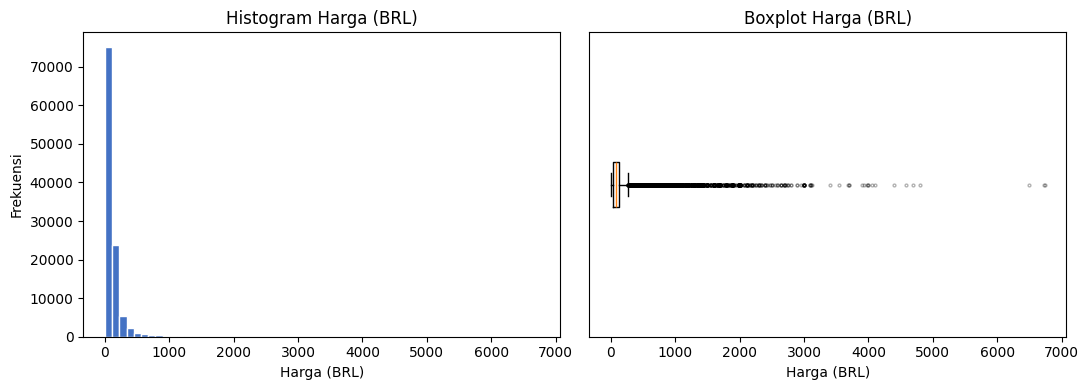

In [44]:
plot_deskriptif("price")

### Gambar 2. Histogram dan boxplot ongkos kirim

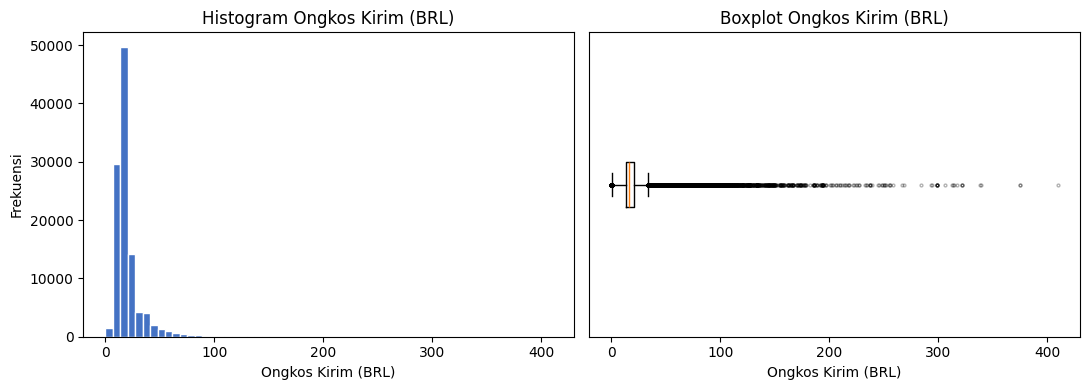

In [45]:
plot_deskriptif("freight_value")

### Gambar 3. Histogram dan boxplot waktu pengiriman

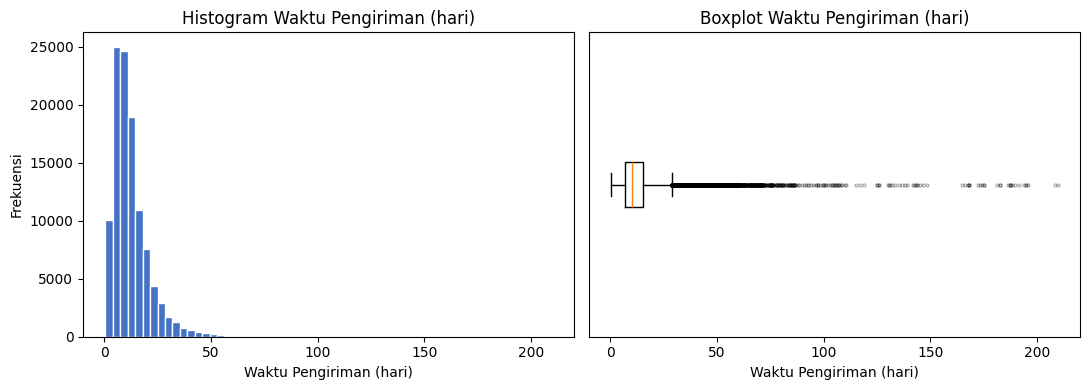

In [46]:
plot_deskriptif("waktu_pengiriman_hari")

## 5. Distribusi Probabilitas
Membandingkan Log-normal, Gamma, dan Eksponensial. Uji KS dilakukan pada sampel acak 5.000 data karena pada data besar uji KS hampir selalu menolak.

In [50]:
kandidat = {"Log-normal": stats.lognorm,
            "Gamma": stats.gamma,
            "Eksponensial": stats.expon}
params = {}      # simpan parameter hasil fit (berguna untuk grafik nanti)
baris = []

for v in VAR:
    x = df[v][df[v] > 0]          # distribusi ini hanya terdefinisi untuk nilai > 0
    for nama, d in kandidat.items():
        par = d.fit(x, floc=0)    # loc dikunci 0 (distribusi mulai dari 0)
        params[(v, nama)] = par

        k = len(par) - 1          # jumlah parameter bebas (loc dikunci, tidak dihitung)
        loglik = d.logpdf(x, *par).sum()
        aic = 2 * k - 2 * loglik

        baris.append({"Variabel": NAMA[v], "Distribusi": nama, "n": len(x),
                      "k": k, "Log-Likelihood": loglik, "AIC": aic})

distribusi = pd.DataFrame(baris)

# Selisih AIC terhadap distribusi terbaik di tiap variabel
distribusi["Delta AIC"] = distribusi["AIC"] - distribusi.groupby("Variabel")["AIC"].transform("min")
distribusi["Terbaik"] = distribusi["Delta AIC"] == 0

distribusi = distribusi.round(3)
distribusi

,Variabel,Distribusi,n,k,Log-Likelihood,AIC,Delta AIC,Terbaik
0,Harga (BRL),Log-normal,110189,2,-622857.345,1245718.690,0.000,True
1,Harga (BRL),Gamma,110189,2,-636636.559,1273277.119,27558.429,False
2,Harga (BRL),Eksponensial,110189,1,-637697.667,1275397.334,29678.644,False
3,Ongkos Kirim (BRL),Log-normal,109808,2,-400817.624,801639.249,0.000,True
4,Ongkos Kirim (BRL),Gamma,109808,2,-408239.669,816483.338,14844.089,False
5,Ongkos Kirim (BRL),Eksponensial,109808,1,-438862.620,877727.239,76087.990,False
6,Waktu Pengiriman (hari),Log-normal,110189,2,-367205.323,734414.646,0.000,True
7,Waktu Pengiriman (hari),Gamma,110189,2,-369307.012,738618.024,4203.378,False
8,Waktu Pengiriman (hari),Eksponensial,110189,1,-388251.394,776504.788,42090.142,False


In [51]:
# Fungsi untuk grafik pencocokan distribusi
def plot_distribusi(v):
    x = df[v][df[v] > 0]
    x = x[x <= x.quantile(.99)]                      # potong di kuantil 99%
    grid = np.linspace(x.min(), x.max(), 300)

    plt.figure(figsize=(7, 4.5))
    plt.hist(x, bins=60, density=True, color="#BDD7EE", edgecolor="white", label="Data")
    for nama, d in kandidat.items():
        plt.plot(grid, d.pdf(grid, *params[(v, nama)]), label=nama)

    plt.title(f"Pencocokan Distribusi: {NAMA[v]}")
    plt.xlabel(NAMA[v]); plt.ylabel("Densitas"); plt.legend(); plt.tight_layout()
    os.makedirs("hasil_analisis", exist_ok=True)
    plt.savefig(f"hasil_analisis/distribusi_{v}.png", dpi=150)
    plt.show()

### Gambar 4. Pencocokan distribusi harga

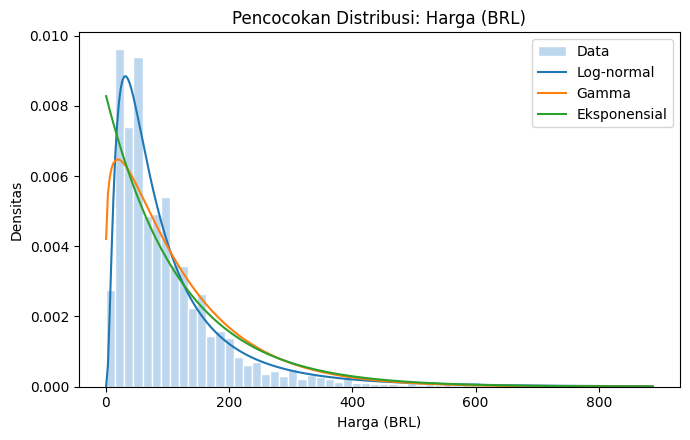

In [52]:
plot_distribusi("price")

### Gambar 5. Pencocokan distribusi ongkos kirim

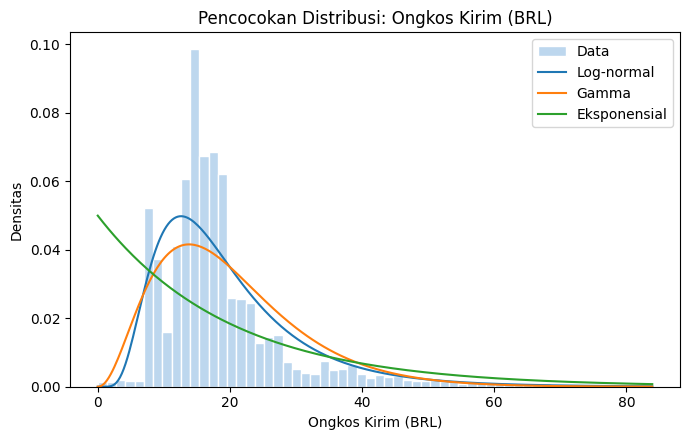

In [53]:
plot_distribusi("freight_value")

### Gambar 6. Pencocokan distribusi waktu pengiriman

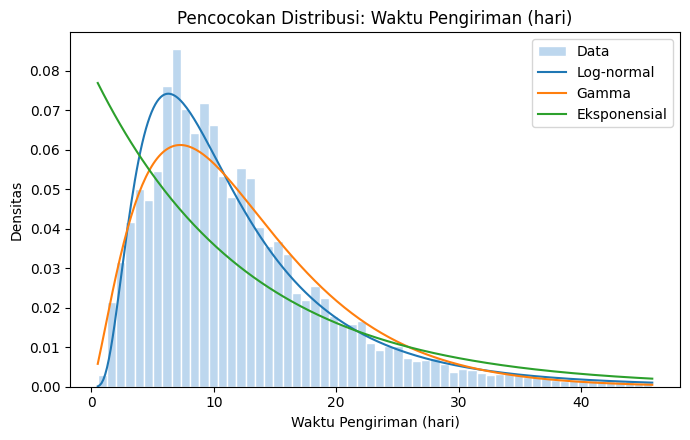

In [54]:
plot_distribusi("waktu_pengiriman_hari")

## 6. Statistika Inferensial

### 6.1 Interval kepercayaan 95% untuk rata-rata

In [23]:
data = df[VAR]            # VAR = ["price", "freight_value", "waktu_pengiriman_hari"]

n = data.count()
mean = data.mean()
se = data.sem()           # standard error = std / akar(n)

# Interval kepercayaan 95% memakai distribusi t
bawah, atas = stats.t.interval(0.95, n - 1, loc=mean, scale=se)

ci = pd.DataFrame({
    "n": n,
    "Mean": mean,
    "SE": se,
    "CI 95% bawah": bawah,
    "CI 95% atas": atas,
    "Margin of Error": (atas - bawah) / 2,
}).round(4)

ci.index = ci.index.map(NAMA)
ci

,n,Mean,SE,CI 95% bawah,CI 95% atas,Margin of Error
Harga (BRL),110189,119.9779,0.5492,118.9015,121.0544,1.0764
Ongkos Kirim (BRL),110189,19.9489,0.0473,19.8562,20.0416,0.0927
Waktu Pengiriman (hari),110189,12.4722,0.0285,12.4165,12.5280,0.0558


### 6.2 Korelasi

In [26]:
# Pasangan variabel yang dikorelasikan
pairs = [("price", "freight_value"),
         ("price", "waktu_pengiriman_hari"),
         ("freight_value", "waktu_pengiriman_hari")]

baris = []
for a, b in pairs:
    r, p = stats.pearsonr(df[a], df[b])
    rs, ps = stats.spearmanr(df[a], df[b])
    baris.append({"Pasangan": f"{a} - {b}",
                  "Pearson r": r, "p Pearson": p,
                  "Spearman rho": rs, "p Spearman": ps})

korelasi = pd.DataFrame(baris).round(4)
korelasi

,Pasangan,Pearson r,p Pearson,Spearman rho,p Spearman
0,price - freight_value,0.4127,0.0,0.4339,0.0
1,price - waktu_pengiriman_hari,0.0624,0.0,0.1154,0.0
2,freight_value - waktu_pengiriman_hari,0.2147,0.0,0.4231,0.0


### Gambar 7. Heatmap korelasi Spearman

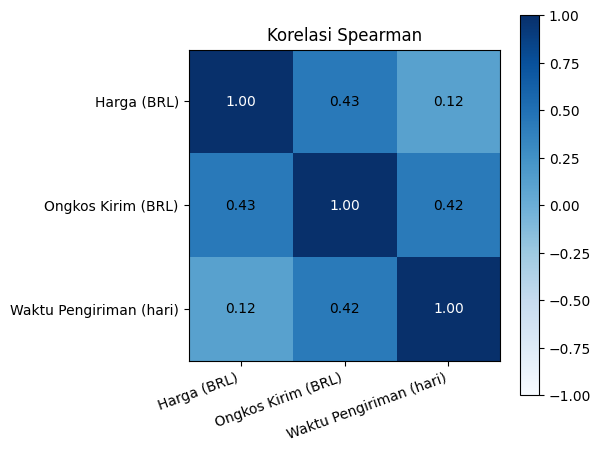

In [55]:
m = df[VAR].corr(method="spearman")
label = [NAMA[v] for v in VAR]

plt.figure(figsize=(6, 5))
plt.imshow(m, cmap="Blues", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(3), label, rotation=20, ha="right")
plt.yticks(range(3), label)

for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center",
                 color="white" if m.iloc[i, j] > 0.6 else "black")

plt.title("Korelasi Spearman"); plt.tight_layout()
os.makedirs("hasil_analisis", exist_ok=True)
plt.savefig("hasil_analisis/korelasi_heatmap.png", dpi=150)
plt.show()

### Gambar 8. Diagram pencar ongkos kirim terhadap waktu pengiriman

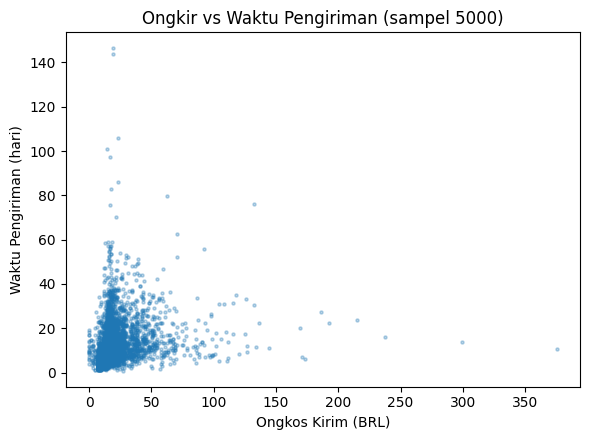

In [56]:
s = df.sample(5000, random_state=42)

plt.figure(figsize=(6, 4.5))
plt.scatter(s["freight_value"], s["waktu_pengiriman_hari"], s=5, alpha=.3)
plt.xlabel("Ongkos Kirim (BRL)")
plt.ylabel("Waktu Pengiriman (hari)")
plt.title("Ongkir vs Waktu Pengiriman (sampel 5000)")
plt.tight_layout()

os.makedirs("hasil_analisis", exist_ok=True)
plt.savefig("hasil_analisis/scatter_ongkir_waktu.png", dpi=150)
plt.show()

### 6.3 Uji hipotesis
**H0:** rata-rata waktu pengiriman kelompok ongkir tinggi = kelompok ongkir rendah  
**H1:** rata-rata waktu pengiriman kelompok ongkir tinggi > kelompok ongkir rendah  
Kelompok dibagi di median ongkir. Taraf signifikansi 0,05.

In [34]:
# 1. Bagi data berdasarkan median freight_value
med = df["freight_value"].median()
tinggi = df.loc[df["freight_value"] > med, "waktu_pengiriman_hari"]
rendah = df.loc[df["freight_value"] <= med, "waktu_pengiriman_hari"]

# 2. Dua uji satu arah (alternative="greater" -> tinggi > rendah)
t, p_t = stats.ttest_ind(tinggi, rendah, equal_var=False, alternative="greater")
u, p_u = stats.mannwhitneyu(tinggi, rendah, alternative="greater")

# 3. Rangkum ke DataFrame
hipotesis = pd.DataFrame([
    ["Welch t-test (satu arah)",   len(tinggi), len(rendah), tinggi.mean(),   rendah.mean(),   t, p_t],
    ["Mann-Whitney U (satu arah)", len(tinggi), len(rendah), tinggi.median(), rendah.median(), u, p_u],
], columns=["Uji", "n ongkir tinggi", "n ongkir rendah",
            "Mean/Median tinggi", "Mean/Median rendah", "Statistik", "p-value"]).round(4)

hipotesis["Keputusan (alpha 0.05)"] = np.where(hipotesis["p-value"] < 0.05,
                                               "Tolak H0", "Gagal tolak H0")

print("Median ongkir (pembagi kelompok):", round(med, 2))
hipotesis

Median ongkir (pembagi kelompok): 16.26


,Uji,n ongkir tinggi,n ongkir rendah,Mean/Median tinggi,Mean/Median rendah,Statistik,p-value,Keputusan (alpha 0.05)
0,Welch t-test (satu arah),55028,55161,15.0211,9.9295,9.287390e+01,0.0,Tolak H0
1,Mann-Whitney U (satu arah),55028,55161,12.5900,8.0900,2.117391e+09,0.0,Tolak H0


## 7. Simpan Hasil

In [57]:
import shutil
with pd.ExcelWriter("hasil_analisis/hasil_analisis.xlsx") as w:
    deskriptif.to_excel(w, sheet_name="Deskriptif", index=False)
    distribusi.to_excel(w, sheet_name="Distribusi", index=False)
    ci.to_excel(w, sheet_name="Interval Kepercayaan", index=False)
    korelasi.to_excel(w, sheet_name="Korelasi", index=False)
    hipotesis.to_excel(w, sheet_name="Uji Hipotesis", index=False)

# 2. Kompres folder hasil_analisis menjadi hasil_analisis.zip
shutil.make_archive("hasil_analisis", "zip", "hasil_analisis")

# 3. Unduh file zip
files.download("hasil_analisis.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>